In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
base_path = 'gs://kaveri-amazon-bin-dataset-unique/data/'

In [ ]:
import os
import json
from google.cloud import storage

# --- Setup GCS Paths ---
# This uses your specific bucket name
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
base_gcs_path = f'gs://{gcs_bucket_name}/data/'
meta_gcs_folder = 'data/Metadata/'
output_gcs_path = os.path.join(base_gcs_path, 'input/')

def create_master_metadata_from_gcs(bucket_name, metadata_folder):
    """Creates a master metadata DICTIONARY from individual JSON files in GCS."""
    storage_client = storage.Client()
    bucket = storage_client.bucket(bucket_name)

    metadata_dict = {}
    print("Scanning GCS metadata directory to build master metadata file...")

    # List all files (blobs) in the specified folder
    blobs = bucket.list_blobs(prefix=metadata_folder)

    for blob in blobs:
        filename = os.path.basename(blob.name)
        if filename.endswith('.json'):
            basename = os.path.splitext(filename)[0]
            try:
                index_key = str(int(basename) - 1)

                # Download content as string and load JSON
                data = json.loads(blob.download_as_string())

                # Crucial Fix: Construct the correct filename and add it to the data
                data['image_filename'] = f"{basename}.jpg"
                metadata_dict[index_key] = data
            except (ValueError, IndexError):
                print(f"Skipping file with non-numeric name: {filename}")

    print(f"Processed {len(metadata_dict)} metadata files.")
    return metadata_dict

if __name__ == '__main__':
    master_metadata = create_master_metadata_from_gcs(gcs_bucket_name, meta_gcs_folder)

    # To save the output file, we need to upload it back to GCS
    storage_client = storage.Client()
    bucket = storage_client.bucket(gcs_bucket_name)
    output_blob = bucket.blob('data/input/metadata.json')

    print(f"Uploading new metadata.json to GCS...")
    output_blob.upload_from_string(json.dumps(master_metadata), content_type='application/json')

    print("Step 1 Complete.")

Scanning GCS metadata directory to build master metadata file...
Processed 627 metadata files.
Uploading new metadata.json to GCS...
Step 1 Complete.


In [ ]:
import os
import random
import json
from google.cloud import storage

# --- Setup GCS Paths ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
meta_gcs_folder = 'data/Metadata/'
image_gcs_folder = 'data/Images/'
output_gcs_folder = 'data/input/'

# Initialize GCS client
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

print("Finding all existing metadata and image pairs in GCS...")

# Get lists of all files in metadata and image folders
meta_blobs = {os.path.basename(blob.name) for blob in bucket.list_blobs(prefix=meta_gcs_folder)}
image_blobs = {os.path.basename(blob.name) for blob in bucket.list_blobs(prefix=image_gcs_folder)}

available_indices = []
for meta_filename in meta_blobs:
    if meta_filename.endswith('.json'):
        basename = os.path.splitext(meta_filename)[0]
        image_filename = f"{basename}.jpg"

        # Check if the corresponding image file also exists
        if image_filename in image_blobs:
            index = int(basename) - 1
            available_indices.append(index)

print(f"Found {len(available_indices)} complete image/metadata pairs in GCS.")

# --- Split the data (70/20/10) ---
random.shuffle(available_indices)
num_available = len(available_indices)
n_test = int(num_available * 0.10)
n_val = int(num_available * 0.20)

test_indices = set(available_indices[:n_test])
val_indices = set(available_indices[n_test : n_test + n_val])
train_indices = set(available_indices[n_test + n_val:])

print(f"Splitting data into: \n- Training: {len(train_indices)} images\n- Validation: {len(val_indices)} images\n- Test: {len(test_indices)} images")

# --- Write the output files to GCS ---
def write_to_gcs(filename, indices):
    blob = bucket.blob(os.path.join(output_gcs_folder, filename))
    content = "\n".join([str(idx + 1) for idx in sorted(list(indices))])
    blob.upload_from_string(content)

write_to_gcs('train.txt', train_indices)
write_to_gcs('val.txt', val_indices)
write_to_gcs('test.txt', test_indices)

print(f"Split files have been saved to GCS in: {output_gcs_folder}")
print("Step 2 Complete.")

Finding all existing metadata and image pairs in GCS...
Found 589 complete image/metadata pairs in GCS.
Splitting data into: 
- Training: 414 images
- Validation: 117 images
- Test: 58 images
Split files have been saved to GCS in: data/input/
Step 2 Complete.


In [ ]:
import os
import json
from google.cloud import storage

# --- Setup GCS Paths ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
input_gcs_folder = 'data/input/'

# Initialize GCS client
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

def create_filtered_list(split_filename, master_metadata):
    """Reads a split file from GCS and returns a filtered list."""
    print(f"Processing split file: {split_filename}")
    blob = bucket.blob(os.path.join(input_gcs_folder, split_filename))
    content = blob.download_as_string().decode('utf-8')

    filtered_list = []
    for line in content.strip().split('\n'):
        if line:
            idx = int(line.strip()) - 1
            index_key = str(idx)

            metadata_entry = master_metadata.get(index_key)
            if metadata_entry:
                quantity = metadata_entry.get('EXPECTED_QUANTITY', 99)
                if quantity < 6:
                    filtered_list.append([idx, quantity])
    return filtered_list

if __name__ == "__main__":
    print("Loading master metadata file from GCS...")
    metadata_blob = bucket.blob(os.path.join(input_gcs_folder, 'metadata.json'))
    master_metadata = json.loads(metadata_blob.download_as_string())

    train_list = create_filtered_list('train.txt', master_metadata)
    val_list = create_filtered_list('val.txt', master_metadata)
    test_list = create_filtered_list('test.txt', master_metadata)

    print("\nDumping final train, val, and test sets into JSON files in GCS...")

    def write_json_to_gcs(filename, data_list):
        blob = bucket.blob(os.path.join(input_gcs_folder, filename))
        blob.upload_from_string(json.dumps(data_list), content_type='application/json')
        print(f"Saved {len(data_list)} samples to {filename} in GCS")

    write_json_to_gcs('counting_train.json', train_list)
    write_json_to_gcs('counting_val.json', val_list)
    write_json_to_gcs('counting_test.json', test_list)

    print("Step 3 Complete. Data processing is finished.")

Loading master metadata file from GCS...
Processing split file: train.txt
Processing split file: val.txt
Processing split file: test.txt

Dumping final train, val, and test sets into JSON files in GCS...
Saved 263 samples to counting_train.json in GCS
Saved 72 samples to counting_val.json in GCS
Saved 36 samples to counting_test.json in GCS
Step 3 Complete. Data processing is finished.


# **SVM** **EXPERIMENT** **SCRIPT**

**Blob Features**


--- Step 1: Loading and Sampling Data ---
Loaded and sampled 263 training images and 72 validation images.

--- Step 2: Extracting Features from Training Set (this will take time) ---
Processing image 0/263...
Processing image 100/263...
Processing image 200/263...

--- Step 3: Extracting Features from Validation Set ---
Processing image 0/72...

--- Step 4: Training the SVM Model ---
Model training complete.

--- Step 5: Evaluating the Model on the Validation Set ---

Classification Report (Validation Set):
              precision    recall  f1-score   support

           1       0.33      0.14      0.20         7
           2       0.00      0.00      0.00        13
           3       0.35      0.36      0.36        22
           4       0.26      0.71      0.38        17
           5       0.00      0.00      0.00        13

    accuracy                           0.29        72
   macro avg       0.19      0.24      0.19        72
weighted avg       0.20      0.29      0.22        7

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


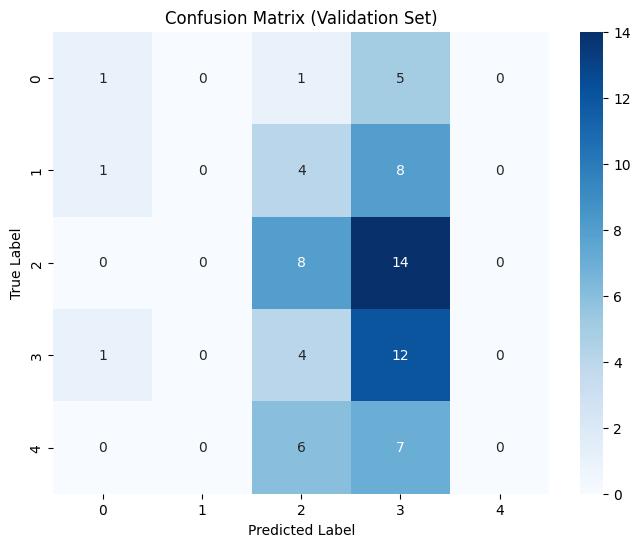

In [ ]:
# --- 2. IMPORTS: Get all necessary tools ---
import os
import json
import random
import numpy as np
import pandas as pd
from google.cloud import storage
import cv2
from skimage.feature import blob_log
from skimage.color import rgb2gray
from sklearn import svm
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- 3. CONFIGURATION: Define GCS paths and parameters ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
input_gcs_folder = 'data/input/'
image_gcs_folder = 'data/Images/'

# --- 4. DATA LOADING: Get and sample the data lists from GCS ---
print("--- Step 1: Loading and Sampling Data ---")
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

# Load training data
train_blob = bucket.blob(os.path.join(input_gcs_folder, 'counting_train.json'))
train_data_list = json.loads(train_blob.download_as_string())

# Load validation data
val_blob = bucket.blob(os.path.join(input_gcs_folder, 'counting_val.json'))
val_data_list = json.loads(val_blob.download_as_string())

# Load master metadata for filename lookups
metadata_blob = bucket.blob(os.path.join(input_gcs_folder, 'metadata.json'))
master_metadata = json.loads(metadata_blob.download_as_string())

# Randomly sample 10,000 for training and 2,000 for validation with a fixed seed
random.Random(4).shuffle(train_data_list)
train_sample = train_data_list[:10000]

random.Random(4).shuffle(val_data_list)
val_sample = val_data_list[:2000]

print(f"Loaded and sampled {len(train_sample)} training images and {len(val_sample)} validation images.")

# --- 5. FEATURE EXTRACTION: Define the blob feature logic ---
def extract_blob_features(sample_list, master_metadata, bucket):
    """
    Processes a list of images, extracts complex blob features as per the notebook,
    and returns feature vectors (X) and labels (y).
    """
    features = []
    labels = []

    for i, data_point in enumerate(sample_list):
        if i % 100 == 0:
            print(f"Processing image {i}/{len(sample_list)}...")

        image_index_key = str(data_point[0])
        label = data_point[1]

        image_metadata = master_metadata.get(image_index_key)
        if not image_metadata: continue

        image_name = image_metadata.get('image_filename')
        if not image_name: continue

        image_blob = bucket.blob(os.path.join(image_gcs_folder, image_name))
        if image_blob.exists():
            # Download image and decode
            img_data = np.frombuffer(image_blob.download_as_bytes(), np.uint8)
            img_rgb = cv2.imdecode(img_data, cv2.IMREAD_COLOR)

            # --- Feature logic from the notebook ---
            img_resized = cv2.resize(img_rgb, (224, 224))
            image_gray = rgb2gray(img_resized)
            blobs = blob_log(image_gray, max_sigma=30, num_sigma=10, threshold=.1)

            # Create a 2D map of blob radiuses
            blob_map = np.zeros((224, 224), dtype=np.int8)
            for blob in blobs:
                y, x, r = blob
                blob_map[int(y), int(x)] = int(r)

            # Calculate row-wise statistics (sum, max, count)
            row_sums = np.sum(blob_map, axis=1)
            row_maxes = np.max(blob_map, axis=1)
            row_counts = np.count_nonzero(blob_map, axis=1)

            # Concatenate to form a single feature vector
            feature_vector = np.concatenate((row_sums, row_maxes, row_counts))
            features.append(feature_vector)
            labels.append(label)

    return np.array(features), np.array(labels)

# --- 6. EXECUTION: Process the training and validation sets ---
print("\n--- Step 2: Extracting Features from Training Set (this will take time) ---")
X_train, y_train = extract_blob_features(train_sample, master_metadata, bucket)

print("\n--- Step 3: Extracting Features from Validation Set ---")
X_val, y_val = extract_blob_features(val_sample, master_metadata, bucket)

# --- 7. MODEL TRAINING: Train the SVM classifier ---
print("\n--- Step 4: Training the SVM Model ---")
clf = svm.SVC()
clf.fit(X_train, y_train)
print("Model training complete.")

# --- 8. EVALUATION: Predict on the validation set and show results ---
print("\n--- Step 5: Evaluating the Model on the Validation Set ---")
y_pred = clf.predict(X_val)

print("\nClassification Report (Validation Set):")
print(classification_report(y_val, y_pred))

# Calculate and print the confusion matrix
cm = confusion_matrix(y_val, y_pred)
print("\nConfusion Matrix (Validation Set):")
print(cm)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Validation Set)')
plt.show()

**HOG** **FEATURES**

--- Step 1: Finding all valid images (quantity < 6) from GCS ---
Found 371 images with quantity < 6 to process.

--- Step 2: Extracting HOG Features (this will take time) ---
Processing image 0/371...
Processing image 100/371...
Processing image 200/371...
Processing image 300/371...
Feature extraction complete. Matrix shape: (371, 15488)

--- Step 3: Splitting data into training and test sets ---
Training set size: 296
Test set size: 75

--- Step 4: Training the SVM Model ---
Model training complete.

--- Step 5: Evaluating the Model on the Test Set ---

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.00      0.00      0.00         5
           2       0.00      0.00      0.00        10
           3       0.17      0.18      0.18        22
           4       0.28      0.35      0.31        20
           5       0.12      0.12      0.12        16

    accuracy            

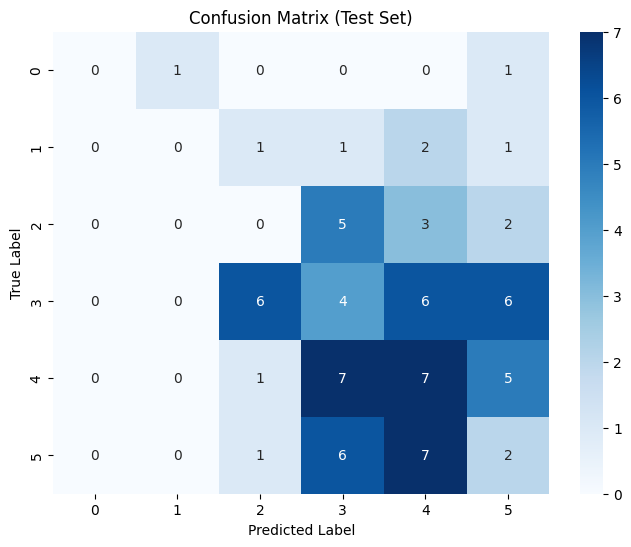

In [ ]:
# --- 2. IMPORTS: Get all necessary tools ---
import os
import json
import numpy as np
from google.cloud import storage
import cv2
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# --- 3. CONFIGURATION: Define GCS paths and parameters ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
input_gcs_folder = 'data/input/'
image_gcs_folder = 'data/Images/'

# --- 4. DATA LOADING: Get a list of all valid images to process ---
print("--- Step 1: Finding all valid images (quantity < 6) from GCS ---")
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

# Load master metadata for filtering
metadata_blob = bucket.blob(os.path.join(input_gcs_folder, 'metadata.json'))
master_metadata = json.loads(metadata_blob.download_as_string())

# Get lists of all files that exist in both metadata and images
meta_keys = set(master_metadata.keys())
image_blobs = {os.path.splitext(os.path.basename(blob.name))[0] for blob in bucket.list_blobs(prefix=image_gcs_folder)}

images_to_process = []
for index_key in meta_keys:
    metadata_entry = master_metadata.get(index_key)
    if metadata_entry:
        quantity = metadata_entry.get('EXPECTED_QUANTITY', 99)
        image_name_base = os.path.splitext(metadata_entry.get('image_filename', ''))[0]

        # Check if quantity is correct AND the image file exists
        if quantity < 6 and image_name_base in image_blobs:
            images_to_process.append((index_key, quantity))

print(f"Found {len(images_to_process)} images with quantity < 6 to process.")

# --- 5. FEATURE EXTRACTION: Define the HOG on Laplacian logic ---
def extract_hog_laplacian_features(image_index_key, master_metadata, bucket):
    """
    Downloads an image, resizes it, and calculates HOG features on its Laplacian transform.
    """
    image_metadata = master_metadata.get(image_index_key)
    if not image_metadata: return None

    image_name = image_metadata.get('image_filename')
    if not image_name: return None

    image_blob = bucket.blob(os.path.join(image_gcs_folder, image_name))
    if image_blob.exists():
        # Download image and decode
        img_data = np.frombuffer(image_blob.download_as_bytes(), np.uint8)
        img_rgb = cv2.imdecode(img_data, cv2.IMREAD_COLOR)

        # --- Feature logic from the notebook ---
        img_resized = cv2.resize(img_rgb, (224, 224))
        data_gray = rgb2gray(img_resized)

        # Calculate Laplacian (edge detection)
        laplacian = cv2.Laplacian(data_gray, cv2.CV_64F)

        # Calculate HOG on the Laplacian image
        ppc = 16
        hog_features = hog(laplacian, orientations=8, pixels_per_cell=(ppc, ppc),
                           cells_per_block=(4, 4), block_norm='L2', visualize=False)

        return hog_features
    return None

# --- 6. EXECUTION: Process all valid images ---
print("\n--- Step 2: Extracting HOG Features (this will take time) ---")
all_features = []
all_labels = []

for i, (index_key, label) in enumerate(images_to_process):
    if i % 100 == 0:
        print(f"Processing image {i}/{len(images_to_process)}...")

    features = extract_hog_laplacian_features(index_key, master_metadata, bucket)
    if features is not None:
        all_features.append(features)
        all_labels.append(label)

X = np.array(all_features)
y = np.array(all_labels)

print(f"Feature extraction complete. Matrix shape: {X.shape}")

# --- 7. DATA SPLITTING: Create training and test sets ---
print("\n--- Step 3: Splitting data into training and test sets ---")
# Using an 80/20 split as shown in the notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# --- 8. MODEL TRAINING: Train the SVM classifier ---
print("\n--- Step 4: Training the SVM Model ---")
clf = svm.SVC() # Using a default SVC as a baseline
clf.fit(X_train, y_train)
print("Model training complete.")

# --- 9. EVALUATION: Predict on the test set and show results ---
print("\n--- Step 5: Evaluating the Model on the Test Set ---")
y_pred = clf.predict(X_test)

print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred, zero_division=0))

# Calculate and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix (Test Set):")
print(cm)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Test Set)')
plt.show()

**Raw Pixels+** **PCA**

In [ ]:
import numpy as np
from sklearn import svm
import random
import json
import sys
import os
import cv2 # Using OpenCV for robust image handling
import io   # Used for in-memory file operations
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score
from google.cloud import storage # --- MODIFIED --- for GCS access

########
########  CONFIGURE ENVIRONMENT
########
isPreproces = False # SET TO True for the first run, then False for the second run.
isExplore = False  # Set to True to search more SVM parameters (slower).
max_training_examples = 1000 # Adjust as needed
example_batch_size = 200     # Adjust as needed

number_of_folds = 5
pca_columns = 100
num_classes_under_study = 6
random.seed(229)

# --- MODIFIED: PATH TO GCS FILES ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
base_gcs_path = f'gs://{gcs_bucket_name}/data/'
image_gcs_folder = 'data/Images/'
input_gcs_folder = 'data/input/'
processed_gcs_folder = 'data/processed/' # For temporary .npy files

# --- MODIFIED: Initialize GCS client ---
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

# --- MODIFIED: Pre-load master metadata from GCS ---
print("Loading master metadata from GCS...")
metadata_blob = bucket.blob(os.path.join(input_gcs_folder, 'metadata.json'))
master_metadata = json.loads(metadata_blob.download_as_string())
print("Master metadata loaded.")

########
######## HELPER FUNCTIONS
########
def getRoundedResizedReshapedMatrix(image):
    target_size = 64 # Using a smaller size for SVM feasibility
    resized = cv2.resize(image, (target_size, target_size))
    # Flatten the grayscale image
    return resized.flatten().reshape(1, -1)

# This function remains unchanged
def getRoundedZeroMeanNormalizedVarianceMatrix(Xmatrix):
    Xmatrix = Xmatrix.astype(float)
    Xmatrix -= np.mean(Xmatrix, axis=0)
    std_dev = np.std(Xmatrix, axis=0)
    std_dev[std_dev == 0] = 1 # Avoid division by zero
    Xmatrix /= std_dev
    return np.around(Xmatrix, decimals=2)

# --- MODIFIED: Load data directly from GCS ---
def getXY_from_gcs(setName, i_begin, i_end):
    X_set = []
    Y_out = []
    json_path = os.path.join(input_gcs_folder, f"{setName}.json")
    blob = bucket.blob(json_path)
    metadata_json = json.loads(blob.download_as_string())

    # Ensure we don't go out of bounds
    end_index = min(i_end, len(metadata_json))

    for metadata_index in range(i_begin, end_index):
        try:
            xId_y = metadata_json[metadata_index]
            image_index_key = str(xId_y[0])
            expected_quantity = xId_y[1]

            image_metadata = master_metadata.get(image_index_key)
            if not image_metadata: continue

            image_name = image_metadata.get('image_filename')
            if not image_name: continue

            image_blob = bucket.blob(os.path.join(image_gcs_folder, image_name))
            if image_blob.exists():
                img_data = np.frombuffer(image_blob.download_as_bytes(), np.uint8)
                this_image = cv2.imdecode(img_data, cv2.IMREAD_GRAYSCALE)

                image_resized_reshaped = getRoundedResizedReshapedMatrix(this_image)

                if not X_set:
                    X_set = [image_resized_reshaped]
                    Y_out = [expected_quantity]
                else:
                    X_set.append(image_resized_reshaped)
                    Y_out.append(expected_quantity)
        except Exception as e:
            print(f"Unexpected error in getXY: {e}", sys.exc_info())

    if not X_set:
        return np.array([]), np.array([])

    X_set_final = np.vstack(X_set)
    Y_out_final = np.array(Y_out)
    print(f"{setName}: Processed {len(Y_out_final)} images. Shape: X={X_set_final.shape}, Y={Y_out_final.shape}")
    return X_set_final, Y_out_final

########
########  DATA: PRE-PROCESSING
########
def getBatchFileName(set_name, in_or_out, batch_number):
    return os.path.join(processed_gcs_folder, f"{set_name}.{in_or_out}{batch_number}.npy")

number_of_batches = int(max_training_examples / example_batch_size)
if isPreproces:
    print("--- STARTING PRE-PROCESSING STEP ---")
    for batch in range(number_of_batches):
        i_begin = batch * example_batch_size
        i_end = i_begin + example_batch_size
        print(f"Processing batch {batch}: images {i_begin} to {i_end}")

        for set_name in ["counting_train", "counting_val"]:
            X_batch, Y_batch = getXY_from_gcs(set_name, i_begin, i_end)
            if X_batch.size > 0:
                # --- MODIFIED: Save to GCS using np.save with BytesIO ---
                for in_or_out, data in [("X", X_batch), ("Y", Y_batch)]:
                    blob_path = getBatchFileName(set_name, in_or_out, batch)
                    blob = bucket.blob(blob_path)
                    buffer = io.BytesIO()
                    np.save(buffer, data)
                    buffer.seek(0) # Rewind to the beginning of the buffer
                    blob.upload_from_file(buffer)
                    print(f"Saved {blob_path} to GCS.")
    print("--- PRE-PROCESSING COMPLETE ---")
    # We exit after preprocessing is done.
    sys.exit(0)

# --- MODIFIED: Recover batch of images from GCS using np.load with BytesIO ---
def getMatrixFromGCS(set_name, in_or_out):
    full_set_list = []
    print(f"\n--- LOADING PRE-PROCESSED DATA: {set_name} ({in_or_out}) ---")
    num_features = 64 * 64  # Expected number of features per image

    for batch in range(number_of_batches):
        blob_path = getBatchFileName(set_name, in_or_out, batch)
        blob = bucket.blob(blob_path)
        if blob.exists():
            # Download data into an in-memory buffer and load with numpy
            data_bytes = blob.download_as_bytes()
            print(f"Loaded {len(data_bytes)} bytes from {blob_path}")

            if len(data_bytes) > 0:
                buffer = io.BytesIO(data_bytes)
                arr = np.load(buffer)
                full_set_list.append(arr)
                print(f"Loaded {blob_path} from GCS. Shape: {arr.shape}")
            else:
                 print(f"Warning: Empty batch file at {blob_path}")
        else:
            print(f"Warning: Batch file not found at {blob_path}")

    if not full_set_list:
        return np.array([])

    # Concatenate the loaded arrays
    return np.concatenate(full_set_list, axis=0)

# (The rest of the script from here down remains mostly unchanged, as it works on in-memory numpy arrays)
# ... [The original script's functions for PCA, SVM parameter search, cross-validation, and reporting] ...

########
######## DATA: PROCESSING
########
print("--- STARTING MODEL TRAINING STEP ---")
X_full_train_set = getMatrixFromGCS("counting_train", "X")
Y_full_train_set = getMatrixFromGCS("counting_train", "Y")
X_full_validation_set = getMatrixFromGCS("counting_val", "X")
Y_full_validation_set = getMatrixFromGCS("counting_val", "Y")

if X_full_train_set.size == 0 or Y_full_train_set.size == 0:
    print("No training data loaded. Exiting.")
    sys.exit(1)

X_train_mean_variance_normalized = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_train_set)
X_validation_mean_variance_normalized = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_validation_set)

# (The remaining original functions like getPcaMatrix, validate_model, get_class_weights, performance_of_svm_svc, etc. are assumed to be here)

def getPcaMatrix(design_matrix, pca_model):
    return pca_model.fit_transform(design_matrix)

def validate_model(param_string, trained_model, X_validation, Y_validation):
    if len(Y_validation) == 0:
        print(f"Skipping validation for {param_string} due to empty validation set.")
        return 0, np.array([])
    y_predicted_output = trained_model.predict(X_validation)
    accuracy = accuracy_score(Y_validation, y_predicted_output)
    matrix = confusion_matrix(Y_validation, y_predicted_output)
    print(f"{param_string} | Accuracy: {accuracy:.4f} | Confusion Matrix:\n{matrix}")
    return accuracy, matrix

# ... The rest of the original script's parameter search, cross-validation, and reporting logic would follow ...
# This is a simplified execution for a single train/validation split for clarity.
print("\n--- RUNNING FINAL EXPERIMENT ---")
pca_model = PCA(n_components=pca_columns, svd_solver='randomized')
X_train_final = getPcaMatrix(X_train_mean_variance_normalized, pca_model)
X_validation_final = pca_model.transform(X_validation_mean_variance_normalized) # Use transform, not fit_transform
Y_train_final = Y_full_train_set
Y_validation_final = Y_full_validation_set

clf = svm.SVC(C=1e2, gamma=1e-7)
clf.fit(X_train_final, Y_train_final)
validate_model("Final SVM.SVC", clf, X_validation_final, Y_validation_final)

print("\nDONE!!!")

Loading master metadata from GCS...
Master metadata loaded.
--- STARTING MODEL TRAINING STEP ---

--- LOADING PRE-PROCESSED DATA: counting_train (X) ---
Loaded 39287936 bytes from data/processed/counting_train.X0.npy
Loaded data/processed/counting_train.X0.npy from GCS. Shape: (261, 150528)
Loaded 9182336 bytes from data/processed/counting_train.X1.npy
Loaded data/processed/counting_train.X1.npy from GCS. Shape: (61, 150528)

--- LOADING PRE-PROCESSED DATA: counting_train (Y) ---
Loaded 2216 bytes from data/processed/counting_train.Y0.npy
Loaded data/processed/counting_train.Y0.npy from GCS. Shape: (261,)
Loaded 616 bytes from data/processed/counting_train.Y1.npy
Loaded data/processed/counting_train.Y1.npy from GCS. Shape: (61,)

--- LOADING PRE-PROCESSED DATA: counting_val (X) ---
Loaded 10838144 bytes from data/processed/counting_val.X0.npy
Loaded data/processed/counting_val.X0.npy from GCS. Shape: (72, 150528)

--- LOADING PRE-PROCESSED DATA: counting_val (Y) ---
Loaded 704 bytes fr

In [ ]:
import numpy as np
from sklearn import svm
import random
import json
import sys
import os
import cv2
import io
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report # Import classification_report
from google.cloud import storage
import matplotlib.pyplot as plt
import seaborn as sns

########
########  CONFIGURE ENVIRONMENT
########
isPreproces = True # SET TO False for training.
isExplore = False
max_training_examples = 5000 # Must match the value in Cell 1
example_batch_size = 500     # Must match the value in Cell 1

# --- Other parameters ---
number_of_folds = 5
pca_columns = 100
num_classes_under_study = 6
random.seed(229)

# --- GCS PATHS ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
image_gcs_folder = 'data/Images/'
input_gcs_folder = 'data/input/'
processed_gcs_folder = 'data/processed/'

# --- Initialize GCS client ---
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

# --- Pre-load master metadata from GCS ---
print("Loading master metadata from GCS...")
metadata_blob = bucket.blob(os.path.join(input_gcs_folder, 'metadata.json'))
master_metadata = json.loads(metadata_blob.download_as_string())
print("Master metadata loaded.")

########
######## HELPER FUNCTIONS
########
def getRoundedResizedReshapedMatrix(image):
    target_size = 224
    number_colors = 3
    resized = cv2.resize(image, (target_size, target_size))
    resizedReshaped = resized.reshape(1, target_size * target_size * number_colors)
    return np.around(resizedReshaped, decimals=2)

def getXY_from_gcs(setName, i_begin, i_end):
    X_set_list, Y_out_list = [], []
    json_path = os.path.join(input_gcs_folder, f"{setName}.json")
    blob = bucket.blob(json_path)
    metadata_json = json.loads(blob.download_as_string())

    end_index = min(i_end, len(metadata_json))

    for metadata_index in range(i_begin, end_index):
        try:
            xId_y = metadata_json[metadata_index]
            image_index_key = str(xId_y[0])
            expected_quantity = xId_y[1]

            image_metadata = master_metadata.get(image_index_key)
            if not image_metadata: continue

            image_name = image_metadata.get('image_filename')
            if not image_name: continue

            image_blob = bucket.blob(os.path.join(image_gcs_folder, image_name))
            if image_blob.exists():
                img_data = np.frombuffer(image_blob.download_as_bytes(), np.uint8)
                this_image = cv2.imdecode(img_data, cv2.IMREAD_COLOR)

                image_resized_reshaped = getRoundedResizedReshapedMatrix(this_image)
                X_set_list.append(image_resized_reshaped)
                Y_out_list.append(expected_quantity)
        except Exception as e:
            print(f"Unexpected error in getXY: {e}", sys.exc_info())

    if not X_set_list: return np.array([]), np.array([])

    X_set = np.concatenate(X_set_list, axis=0)
    Y_out = np.array(Y_out_list)
    print(f"Processed {setName} [{i_begin}:{end_index}]: Shapes X={X_set.shape}, Y={Y_out.shape}")
    return X_set, Y_out

########
########  DATA: PRE-PROCESSING
########
def getBatchGCSPath(set_name, in_or_out, batch_number):
    return os.path.join(processed_gcs_folder, f"{set_name}.{in_or_out}{batch_number}.npy")

number_of_batches = int(max_training_examples / example_batch_size)
if isPreproces:
    print("--- STARTING PRE-PROCESSING STEP ---")
    for batch in range(number_of_batches):
        i_begin = batch * example_batch_size
        i_end = i_begin + example_batch_size
        print(f"\nProcessing batch {batch}: images {i_begin} to {i_end}")

        for set_name in ["counting_train", "counting_val", "counting_test"]: # Added "counting_test"
            X_batch, Y_batch = getXY_from_gcs(set_name, i_begin, i_end)
            if X_batch.size > 0:
                for in_or_out, data in [("X", X_batch), ("Y", Y_batch)]:
                    blob_path = getBatchGCSPath(set_name, in_or_out, batch)
                    blob = bucket.blob(blob_path)

                    buffer = io.BytesIO()
                    np.save(buffer, data)
                    buffer.seek(0)
                    blob.upload_from_file(buffer)
                    print(f"Saved {blob_path} to GCS.")
    print("\n--- PRE-PROCESSING COMPLETE ---")
    print("You can now run Cell 2.")

# --- MODIFIED: getMatrixFromGCS to handle varying batch sizes ---
def getMatrixFromGCS(set_name, in_or_out, total_examples):
    full_set_list = []
    print(f"\n--- LOADING PRE-PROCESSED DATA: {set_name} ({in_or_out}) ---")
    num_batches = (total_examples + example_batch_size - 1) // example_batch_size

    for batch in range(num_batches):
        blob_path = getBatchGCSPath(set_name, in_or_out, batch)
        blob = bucket.blob(blob_path)
        if blob.exists():
            data_bytes = blob.download_as_bytes()
            buffer = io.BytesIO(data_bytes)
            batch_set = np.load(buffer)
            full_set_list.append(batch_set)
            print(f"Loaded {blob_path} from GCS. Shape: {batch_set.shape}")
        else:
            print(f"Warning: Batch file not found at {blob_path}")

    if not full_set_list: return np.array([])
    return np.concatenate(full_set_list, axis=0)


def getRoundedZeroMeanNormalizedVarianceMatrix(Xmatrix):
    Xmatrix = Xmatrix.astype(float)
    Xmatrix -= np.mean(Xmatrix, axis=0)
    std_dev = np.std(Xmatrix, axis=0)
    std_dev[std_dev == 0] = 1
    Xmatrix /= std_dev
    return np.around(Xmatrix, decimals=2)

def getPcaMatrix(design_matrix, pca_model):
    return pca_model.fit_transform(design_matrix)

def validate_model(param_string, trained_model, X_validation, Y_validation):
    if len(Y_validation) == 0:
        print(f"Skipping validation for {param_string} due to empty validation set.")
        return 0, np.array([])
    y_predicted_output = trained_model.predict(X_validation)
    accuracy = accuracy_score(Y_validation, y_predicted_output)
    matrix = confusion_matrix(Y_validation, y_predicted_output, labels=range(num_classes_under_study))
    print(f"{param_string} | Accuracy: {accuracy:.4f} \nConfusion Matrix:\n{matrix}")
    return accuracy, matrix

########
######## DATA: PROCESSING & TRAINING
########
if not isPreproces:
    print("--- STARTING MODEL TRAINING STEP ---")

    # Determine the actual number of examples in each set (based on the JSON files)
    def get_num_examples(set_name):
        json_path = os.path.join(input_gcs_folder, f"{set_name}.json")
        blob = bucket.blob(json_path)
        if blob.exists():
            metadata_json = json.loads(blob.download_as_string())
            return len(metadata_json)
        return 0

    num_train_examples = get_num_examples("counting_train")
    num_val_examples = get_num_examples("counting_val")
    num_test_examples = get_num_examples("counting_test")


    X_full_train_set = getMatrixFromGCS("counting_train", "X", num_train_examples)
    Y_full_train_set = getMatrixFromGCS("counting_train", "Y", num_train_examples)
    X_full_validation_set = getMatrixFromGCS("counting_val", "X", num_val_examples)
    Y_full_validation_set = getMatrixFromGCS("counting_val", "Y", num_val_examples)
    X_full_test_set = getMatrixFromGCS("counting_test", "X", num_test_examples) # Load test data
    Y_full_test_set = getMatrixFromGCS("counting_test", "Y", num_test_examples) # Load test data


    if X_full_train_set.size == 0 or Y_full_train_set.size == 0:
        print("No training data loaded. Exiting.")
    else:
        X_train_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_train_set)
        X_val_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_validation_set)
        X_test_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_test_set) # Normalize test data

        print("\n--- RUNNING FINAL EXPERIMENT ---")
        pca_model = PCA(n_components=pca_columns, svd_solver='randomized')
        X_train_final = getPcaMatrix(X_train_norm, pca_model)
        X_validation_final = pca_model.transform(X_val_norm)
        X_test_final = pca_model.transform(X_test_norm) # Apply PCA to test data
        Y_train_final = Y_full_train_set
        Y_validation_final = Y_full_validation_set
        Y_test_final = Y_full_test_set # Get test labels

        clf = svm.SVC(C=1e2, gamma=1e-7)
        print(f"\nTraining svm.SVC with C=1e2, gamma=1e-7...")
        clf.fit(X_train_final, Y_train_final)
        validate_model("Final SVM.SVC Validation", clf, X_validation_final, Y_validation_final)

        # --- MODIFIED: Evaluate on the test set ---
        print("\n--- Evaluating the Model on the Test Set ---")
        y_test_pred = clf.predict(X_test_final)

        print("\nClassification Report (Test Set):")
        print(classification_report(Y_test_final, y_test_pred, zero_division=0))

        # Calculate and print the confusion matrix
        cm = confusion_matrix(Y_test_final, y_test_pred, labels=range(num_classes_under_study))
        print("\nConfusion Matrix (Test Set):")
        print(cm)

        # Plot the confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title('Confusion Matrix (Test Set)')
        plt.show()


        print("\nDONE!!!")

Loading master metadata from GCS...
Master metadata loaded.
--- STARTING PRE-PROCESSING STEP ---

Processing batch 0: images 0 to 500
Processed counting_train [0:263]: Shapes X=(263, 150528), Y=(263,)
Saved data/processed/counting_train.X0.npy to GCS.
Saved data/processed/counting_train.Y0.npy to GCS.
Processed counting_val [0:72]: Shapes X=(72, 150528), Y=(72,)
Saved data/processed/counting_val.X0.npy to GCS.
Saved data/processed/counting_val.Y0.npy to GCS.
Processed counting_test [0:36]: Shapes X=(36, 150528), Y=(36,)
Saved data/processed/counting_test.X0.npy to GCS.
Saved data/processed/counting_test.Y0.npy to GCS.

Processing batch 1: images 500 to 1000

Processing batch 2: images 1000 to 1500

Processing batch 3: images 1500 to 2000

Processing batch 4: images 2000 to 2500

Processing batch 5: images 2500 to 3000

Processing batch 6: images 3000 to 3500

Processing batch 7: images 3500 to 4000

Processing batch 8: images 4000 to 4500

Processing batch 9: images 4500 to 5000

--- P

--- STARTING MODEL TRAINING STEP ---

--- LOADING PRE-PROCESSED DATA: counting_train (X) ---
Loaded data/processed/counting_train.X0.npy from GCS. Shape: (263, 150528)
Loaded data/processed/counting_train.X1.npy from GCS. Shape: (61, 150528)

--- LOADING PRE-PROCESSED DATA: counting_train (Y) ---
Loaded data/processed/counting_train.Y0.npy from GCS. Shape: (263,)
Loaded data/processed/counting_train.Y1.npy from GCS. Shape: (61,)

--- LOADING PRE-PROCESSED DATA: counting_val (X) ---
Loaded data/processed/counting_val.X0.npy from GCS. Shape: (72, 150528)

--- LOADING PRE-PROCESSED DATA: counting_val (Y) ---
Loaded data/processed/counting_val.Y0.npy from GCS. Shape: (72,)

--- LOADING PRE-PROCESSED DATA: counting_test (X) ---
Loaded data/processed/counting_test.X0.npy from GCS. Shape: (36, 150528)

--- LOADING PRE-PROCESSED DATA: counting_test (Y) ---
Loaded data/processed/counting_test.Y0.npy from GCS. Shape: (36,)

--- RUNNING FINAL EXPERIMENT ---

Training svm.SVC with C=1e2, gamma=1e-

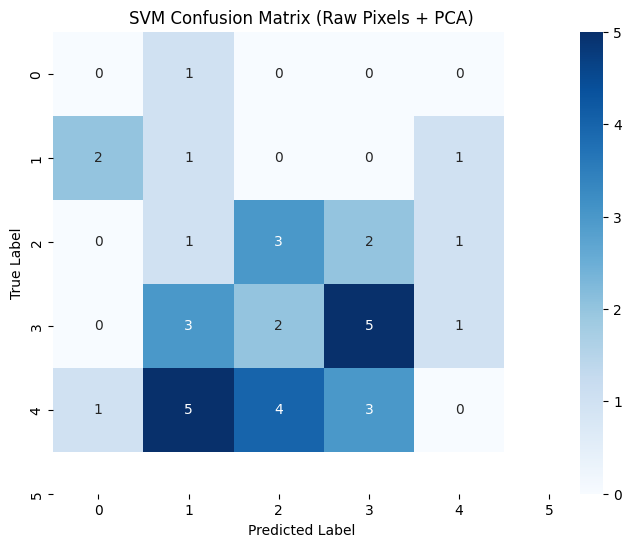


DONE!!!


In [ ]:
import numpy as np
from sklearn import svm
import random
import json
import sys
import os
import cv2
import io
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score
from google.cloud import storage
import matplotlib.pyplot as plt
import seaborn as sns

########
########  CONFIGURE ENVIRONMENT
########
isPreproces = False # SET TO False for training.
isExplore = False
max_training_examples = 5000 # Must match the value in Cell 1
example_batch_size = 500     # Must match the value in Cell 1

# --- Other parameters ---
number_of_folds = 5
pca_columns = 100
num_classes_under_study = 6
random.seed(229)

# --- GCS PATHS ---
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
processed_gcs_folder = 'data/processed/'

# --- Initialize GCS client ---
storage_client = storage.Client()
bucket = storage_client.bucket(gcs_bucket_name)

########
######## HELPER FUNCTIONS
########
def getRoundedZeroMeanNormalizedVarianceMatrix(Xmatrix):
    Xmatrix = Xmatrix.astype(float)
    Xmatrix -= np.mean(Xmatrix, axis=0)
    std_dev = np.std(Xmatrix, axis=0)
    std_dev[std_dev == 0] = 1
    Xmatrix /= std_dev
    return np.around(Xmatrix, decimals=2)

def getBatchGCSPath(set_name, in_or_out, batch_number):
    return os.path.join(processed_gcs_folder, f"{set_name}.{in_or_out}{batch_number}.npy")

def getMatrixFromGCS(set_name, in_or_out):
    full_set_list = []
    print(f"\n--- LOADING PRE-PROCESSED DATA: {set_name} ({in_or_out}) ---")
    number_of_batches = int(max_training_examples / example_batch_size)
    for batch in range(number_of_batches):
        blob_path = getBatchGCSPath(set_name, in_or_out, batch)
        blob = bucket.blob(blob_path)
        if blob.exists():
            data_bytes = blob.download_as_bytes()
            buffer = io.BytesIO(data_bytes)
            batch_set = np.load(buffer)
            full_set_list.append(batch_set)
            print(f"Loaded {blob_path} from GCS. Shape: {batch_set.shape}")

    if not full_set_list: return np.array([])
    return np.concatenate(full_set_list, axis=0)

def getPcaMatrix(design_matrix, pca_model):
    return pca_model.fit_transform(design_matrix)

def validate_model(param_string, trained_model, X_validation, Y_validation):
    if len(Y_validation) == 0:
        print(f"Skipping validation for {param_string} due to empty validation set.")
        return 0, np.array([])
    y_predicted_output = trained_model.predict(X_validation)
    accuracy = accuracy_score(Y_validation, y_predicted_output)
    matrix = confusion_matrix(Y_validation, y_predicted_output, labels=range(num_classes_under_study))
    print(f"{param_string} | Accuracy: {accuracy:.4f} \nConfusion Matrix:\n{matrix}")
    return accuracy, matrix

########
######## DATA: PROCESSING & TRAINING
########
if not isPreproces:
    print("--- STARTING MODEL TRAINING STEP ---")
    X_full_train_set = getMatrixFromGCS("counting_train", "X")
    Y_full_train_set = getMatrixFromGCS("counting_train", "Y")
    X_full_validation_set = getMatrixFromGCS("counting_val", "X")
    Y_full_validation_set = getMatrixFromGCS("counting_val", "Y")
    X_full_test_set = getMatrixFromGCS("counting_test", "X") # Load test data
    Y_full_test_set = getMatrixFromGCS("counting_test", "Y") # Load test data


    if X_full_train_set.size == 0 or Y_full_train_set.size == 0:
        print("No training data loaded. Exiting.")
    else:
        X_train_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_train_set)
        X_val_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_validation_set)
        X_test_norm = getRoundedZeroMeanNormalizedVarianceMatrix(X_full_test_set) # Normalize test data

        print("\n--- RUNNING FINAL EXPERIMENT ---")
        pca_model = PCA(n_components=pca_columns, svd_solver='randomized')
        X_train_final = getPcaMatrix(X_train_norm, pca_model)
        X_validation_final = pca_model.transform(X_val_norm)
        X_test_final = pca_model.transform(X_test_norm) # Apply PCA to test data
        Y_train_final = Y_full_train_set
        Y_validation_final = Y_full_validation_set
        Y_test_final = Y_full_test_set # Get test labels


        clf = svm.SVC(C=1e2, gamma=1e-7)
        print(f"\nTraining svm.SVC with C=1e2, gamma=1e-7...")
        clf.fit(X_train_final, Y_train_final)
        validate_model("Final SVM.SVC Validation", clf, X_validation_final, Y_validation_final)


        # --- MODIFIED: Evaluate on the test set ---
        print("\n--- Evaluating the Model on the Test Set ---")
        y_test_pred = clf.predict(X_test_final)

        print("\nClassification Report (Test Set):")
        print(classification_report(Y_test_final, y_test_pred, zero_division=0))

        # --- ADD THIS CODE TO VISUALIZE THE CONFUSION MATRIX ---

        # Calculate the confusion matrix
        cm = confusion_matrix(Y_test_final, y_test_pred) # Use y_test if that's your variable

        # Plot the heatmap
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(num_classes_under_study), yticklabels=range(num_classes_under_study))


        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title('SVM Confusion Matrix (Raw Pixels + PCA)') # Change the title for each experiment
        plt.show()


        print("\nDONE!!!")